## only attention layer and remove positional embedding and reimplement

In [ ]:
%pip install datasets nltk 
%pip install -q tokenizers
%pip install -U portalocker>=2.0.0

# https://pypi.org/project/torchtext/

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import nltk
nltk.download('punkt')

device = 'cuda' if torch.cuda.is_available() else 'cpu'

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


# 1. Data preparation

In [ ]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")

train_data = imdb["train"]
test_data = imdb["test"]

print(imdb)

In [ ]:
from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.trainers import WordLevelTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import Lowercase

hf_tokenizer = Tokenizer(WordLevel(unk_token="<unk>"))
hf_tokenizer.normalizer = Lowercase()
hf_tokenizer.pre_tokenizer = Whitespace()

vocab_limit = 20000
min_freq = 3

trainer = WordLevelTrainer(
    vocab_size=vocab_limit,
    min_frequency=min_freq,
    special_tokens=["<pad>", "<s>", "<unk>"]
)


hf_tokenizer.train_from_iterator((x["text"] for x in train_data), trainer)

vocab = hf_tokenizer.get_vocab()
vocab_ordered = dict(sorted(vocab.items(), key=lambda x: x[1]))
 
PAD_ID = hf_tokenizer.token_to_id("<pad>")
SOS_ID = hf_tokenizer.token_to_id("<s>")
UNK_ID = hf_tokenizer.token_to_id("<unk>")
 
vocab_size = len(vocab_ordered)

print("HF vocab_size =", vocab_size)
print("SPECIAL:", {"<pad>": PAD_ID, "<s>": SOS_ID, "<unk>": UNK_ID})


HF vocab_size = 20000
SPECIAL: {'<pad>': 0, '<s>': 1, '<unk>': 2}


In [ ]:
import torch

seq_length = 200

def text_pipeline(text: str):
    return hf_tokenizer.encode(text).ids

def collate_batch(batch, seq_length=seq_length):
    text_list, label_list = [], []
    for sample in batch:
        label_list.append(sample["label"])

        ids = text_pipeline(sample["text"])[:seq_length]

        if len(ids) < seq_length:
            pad_size = seq_length - len(ids) - 1
            ids = [PAD_ID] * pad_size + [SOS_ID] + ids

        text_list.append(ids)

    input_ids = torch.tensor(text_list, dtype=torch.int64)
    labels = torch.tensor(label_list, dtype=torch.int64)
    return (input_ids, labels)


In [ ]:
from torch.utils.data import DataLoader
batch_size = 32

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, collate_fn=collate_batch, drop_last=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, collate_fn=collate_batch, drop_last=True)

# 2. Model

In [ ]:
class MyMultiheadAttention(nn.Module):
    def __init__(self, embed_dim, num_heads):
        super(MyMultiheadAttention, self).__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.query_linear = nn.Linear(embed_dim, embed_dim)
        self.key_linear = nn.Linear(embed_dim, embed_dim)
        self.value_linear = nn.Linear(embed_dim, embed_dim)
        self.out_linear = nn.Linear(embed_dim, embed_dim)

    def forward(self, query, key, value):
        batch_size = query.size(0)

        # Linear projections
        query = self.query_linear(query)
        key = self.key_linear(key)
        value = self.value_linear(value)

        # Reshape for multi-head attention
        query = query.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)
        key = key.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)
        value = value.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        scores = torch.matmul(query, key.transpose(-2, -1)) / (self.head_dim ** 0.5)

        attention_weights = F.softmax(scores, dim=-1)
        context = torch.matmul(attention_weights, value)

        # Concatenate heads and apply final linear layer
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.embed_dim)
        output = self.out_linear(context)

        return output, attention_weights

class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout):
        super().__init__()
        self.attn = MyMultiheadAttention(embed_dim=embed_dim, num_heads=num_heads)

        self.layernorm = nn.LayerNorm(normalized_shape=embed_dim, eps=1e-6)
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, query, key, value):
        attn_output, _ = self.attn(query, key, value)
        attn_output = self.dropout(attn_output)
        output = self.layernorm(query + attn_output)
        return output


class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, embed_dim, max_length, device):
        super().__init__()
        self.device = device
        self.word_emb = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embed_dim)

    def forward(self, x):
        output = self.word_emb(x)
        return output


class TransformerTextCls(nn.Module):
    def __init__(self, vocab_size, max_length, embed_dim, num_heads, dropout, device):
        super().__init__()
        self.embd_layer = TokenEmbedding(vocab_size, embed_dim, max_length, device)
        self.transformer_layer = TransformerBlock(embed_dim, num_heads, dropout)

        self.fc = nn.Linear(in_features=200*32, out_features=2)
    def forward(self, x):
        output = self.embd_layer(x)
        output = self.transformer_layer(output, output, output)
        output = nn.Flatten()(output)
        output = self.fc(output)
        return output


In [ ]:
max_length = seq_length #200
embed_dim = 32
num_heads = 2
ff_dim = 32
dropout = 0.1
model = TransformerTextCls(vocab_size, max_length, embed_dim, num_heads, dropout, device)

In [ ]:
# prompt: test model with a random x

import torch

# Generate a random input tensor
x = torch.randint(0, vocab_size, (batch_size, seq_length))

# Move the input tensor to the appropriate device
#x = x.to(device)

# Perform the forward pass
output = model(x)

output.shape

torch.Size([32, 2])

# 3. Evaluate

In [ ]:
def evaluate(model, test_loader, criterion, device):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            test_loss += loss.item()
            correct +=(predicted == labels).sum().item()

    test_loss = test_loss / len(test_loader)
    accuracy = 100* correct / total

    return test_loss, accuracy

# 4. Train

In [ ]:
max_epoch = 15
LR = 0.001
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [ ]:
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []

model.to(device)
for epoch in range(max_epoch):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        running_correct += (predicted == labels).sum().item()

        loss.backward()
        optimizer.step()

    epoch_loss =  running_loss / len(train_loader)
    epoch_accuracy = 100* running_correct / total
    test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

    print(f"Epoch [{epoch + 1}/{max_epoch}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [1/15], Loss: 0.7965, Accuracy: 60.12%, Test Loss: 0.6504, Test Accuracy: 68.46%
Epoch [2/15], Loss: 0.4847, Accuracy: 78.35%, Test Loss: 0.5769, Test Accuracy: 73.95%
Epoch [3/15], Loss: 0.3494, Accuracy: 84.94%, Test Loss: 0.5894, Test Accuracy: 75.91%
Epoch [4/15], Loss: 0.2587, Accuracy: 89.68%, Test Loss: 0.6318, Test Accuracy: 76.32%
Epoch [5/15], Loss: 0.1843, Accuracy: 93.05%, Test Loss: 0.6745, Test Accuracy: 77.23%
Epoch [6/15], Loss: 0.1211, Accuracy: 95.80%, Test Loss: 0.7905, Test Accuracy: 77.62%
Epoch [7/15], Loss: 0.0726, Accuracy: 97.71%, Test Loss: 0.9211, Test Accuracy: 77.07%
Epoch [8/15], Loss: 0.0421, Accuracy: 98.83%, Test Loss: 1.0791, Test Accuracy: 78.41%
Epoch [9/15], Loss: 0.0264, Accuracy: 99.23%, Test Loss: 1.1618, Test Accuracy: 77.58%
Epoch [10/15], Loss: 0.0158, Accuracy: 99.57%, Test Loss: 1.3082, Test Accuracy: 77.56%
Epoch [11/15], Loss: 0.0153, Accuracy: 99.53%, Test Loss: 1.4268, Test Accuracy: 78.42%
Epoch [12/15], Loss: 0.0096, Accuracy: 99

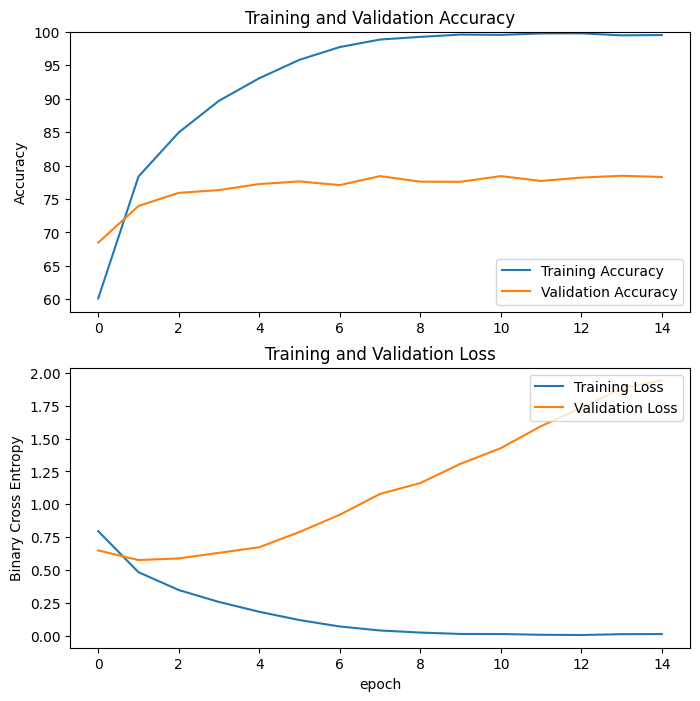

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(test_accuracies, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),100])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(train_losses, label='Training Loss')
plt.plot(test_losses, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Binary Cross Entropy')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()